In [82]:
#Markdown Cell 1: Project Introduction

In [83]:
#Markdown Cell 2: Notebook Workflow and Expected Outputs

## 3. Installing Dependencies

In [84]:
#Installing core packages for the project
%pip install -q pandas openpyxl numpy matplotlib scikit-learn nltk gensim


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [85]:
#Install optional sentiment analysis package for the project
%pip install -q pysentimiento

Note: you may need to restart the kernel to use updated packages.


In [86]:
%pip install -q bertopic


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [87]:
%pip install -q gensim

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 4. Importing Libraries

In [88]:
# Import necessary libraries
# Core Python, file handling, data manipulation, and reproducibility
import os
from pathlib import Path
import glob
import json
import re
import random
import pandas as pd
import numpy as np
import time

# Plotting and visualization
import matplotlib as mpl
import matplotlib.pyplot as plt

# Image loading and inspection
from PIL import Image


# Scikit-learn: text feature extraction, data splitting, label encoding,
# similarity search, and model evaluation
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF
from sklearn.decomposition import TruncatedSVD                                  #for reducing the dimensionality of the sparse TF-IDF matrix when creating a two-dimensional plot.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score                                    #to assess how well-separated the resulting clusters are.
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)
from sklearn.metrics.pairwise import cosine_similarity


# PyTorch: tensor operations and BERT inference
import torch



In [89]:
# Set random seeds for reproducibility
np.random.seed(42)

random.seed(42)

## 5. Loading and Exploring the Data

In [90]:
#setting up the path to the student data file
data_dir = Path("TopicModellingStudentFeedbackData.xlsx")

#reading the first sheet of the excel file
df = pd.read_excel(data_dir, sheet_name="Sheet1")

In [91]:
#getting the dataset shape
print(df.shape)

(1707, 20)


In [92]:
#printing column names - in list format
print(df.columns.tolist())

['Subject Code', 'Gender', 'US_Status', 'Race_Ethnicity', 'FacultySupportResponse', 'FacultySupport_Approach1_Code', 'FacultySupport_Approach2_Code', 'FacutlySupport_MultipleTopics', 'FacultySupport_Ambiguous', 'TASupportResponse', 'TASupport_Approach1_Code', 'TASupport_Approach2_Code', 'TASupport_MultipleTopics', 'TASupport_Ambiguous', 'PeerSupportResponse', 'PeerSupport_Approach1_Code', 'PeerSupport_Approach2_Code', 'PeerSupport_MultipleTopics', 'PeerSupport_Ambiguous', 'COVID_Code']


In [93]:
#retrieving the first 5 rows of the dataset
df.head()

,Subject Code,Gender,US_Status,Race_Ethnicity,FacultySupportResponse,FacultySupport_Approach1_Code,FacultySupport_Approach2_Code,FacutlySupport_MultipleTopics,FacultySupport_Ambiguous,TASupportResponse,TASupport_Approach1_Code,TASupport_Approach2_Code,TASupport_MultipleTopics,TASupport_Ambiguous,PeerSupportResponse,PeerSupport_Approach1_Code,PeerSupport_Approach2_Code,PeerSupport_MultipleTopics,PeerSupport_Ambiguous,COVID_Code
0,1,Male,US Citizen,Non-Hispanic White,"Better handwriting, hard to follow lecture sli...",Teaching Practice,Teaching Practice,No,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PreCOVID
1,2,Male,US Citizen,Asian,Variety of office hours so that all can get he...,Interactions,Interactions,No,No,Variety of office hours so that all can get he...,TA Availability,Interactions,No,No,Communicate,Engagement,Engagement,No,No,PreCOVID
2,3,Male,US Citizen,Non-Hispanic White,"Better lecture, no more ""is that good?""",Teaching Practice,Teaching Practice,No,Yes,Respond to e-mails,Q&A,Interactions,No,No,NaN,NaN,NaN,NaN,NaN,PreCOVID
3,4,Female,US Citizen,Asian,Online resources; post more notes on line,Teaching Practice,Teaching Practice,No,No,examples,Teaching Practice,Examples and Experience,No,No,NaN,NaN,NaN,NaN,NaN,PreCOVID
4,5,Male,International,Asian,It would be better if we can have an equation ...,Examples and Experience,Teaching Practice,No,No,Let students work in groups on questions,Q&A,Interactions,No,No,NaN,NaN,NaN,NaN,NaN,PreCOVID


In [94]:
#now we can get the selected response column and check for null values
faculty_support_response = "FacultySupportResponse"

print(faculty_support_response)

FacultySupportResponse


In [95]:
#checking null & not-null values from the selected response column
print("Not-null responses:", df[faculty_support_response].notna().sum())

print("Null responses:", df[faculty_support_response].isna().sum())


Not-null responses: 1676
Null responses: 31


# EDA (Exploratory Data Analysis)


In [96]:
#dropping unique null values from the selected response column

print(df[faculty_support_response].dropna().nunique())

1671


In [97]:
print(df[faculty_support_response].dropna().duplicated().sum())

5


In [98]:
display(
    df.loc[
        df[faculty_support_response].notna(),                       #filtering out missing responses
        [faculty_support_response]
    ].sample(                                                       #randomly select up to 10 responses
        min(10, df[faculty_support_response].notna().sum()), 
        random_state=42
    )
)

,FacultySupportResponse
879,Professors should understand that the quality ...
1290,I like it when professors try to be as concret...
423,Be more knowledgeable on the homework. I went ...
1321,Assign study group or hold more office hours
1652,Allow for mistakes in homework without impacti...
1419,Give homework and labs that actually relate to...
472,Be open and accessible for asking questions du...
303,Professors can best support their students by ...
1487,"Make lectures recorded, so we can rewatch lect..."
685,"Post lecture slides before class, so we can an..."


## Creating the working dataset

In [99]:
#Creating a working clean table & preserving the original row indices

working_df = df[[faculty_support_response]].copy().rename(
        columns= {faculty_support_response: "raw_response"}
)

working_df.head() #checking the saved variable initially

,raw_response
0,"Better handwriting, hard to follow lecture sli..."
1,Variety of office hours so that all can get he...
2,"Better lecture, no more ""is that good?"""
3,Online resources; post more notes on line
4,It would be better if we can have an equation ...


In [100]:
#preserving the original row index (for traceability purposes) in a new column called "source_row_index"
working_df["source_row_index"] = working_df.index

#removing leading and trailing whitespace
working_df["raw_response"] = (
    working_df["raw_response"].astype("string").str.strip()
)

#converting empty strings into missing values
working_df["raw_response"] = working_df["raw_response"].replace("", pd.NA)

#inspecting the first 5 rows of the working dataframe
working_df.head()


,raw_response,source_row_index
0,"Better handwriting, hard to follow lecture sli...",0
1,Variety of office hours so that all can get he...,1
2,"Better lecture, no more ""is that good?""",2
3,Online resources; post more notes on line,3
4,It would be better if we can have an equation ...,4


In [101]:
working_df.info()  #checkking the data frame info

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1707 entries, 0 to 1706
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   raw_response      1676 non-null   string
 1   source_row_index  1707 non-null   int64 
dtypes: int64(1), string(1)
memory usage: 26.8 KB


In [102]:
#creating a copy of the working dataframe for further processing
copy_df = working_df.dropna(subset = ["raw_response"]).copy()  

copy_df.info()  #checking the data frame info

<class 'pandas.core.frame.DataFrame'>
Index: 1676 entries, 0 to 1706
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   raw_response      1676 non-null   string
 1   source_row_index  1676 non-null   int64 
dtypes: int64(1), string(1)
memory usage: 39.3 KB


In [103]:
copy_df['character_count'] = copy_df['raw_response'].str.len()

copy_df["word_count"] = copy_df["raw_response"].str.split().str.len()

display(
    copy_df[["character_count", "word_count"]].describe().round(2)
    )

,character_count,word_count
count,1676.0,1676.00
mean,139.96,23.64
std,125.31,21.97
min,7.0,1.00
25%,56.0,9.00
50%,102.0,17.00
75%,182.0,31.00
max,1234.0,221.00


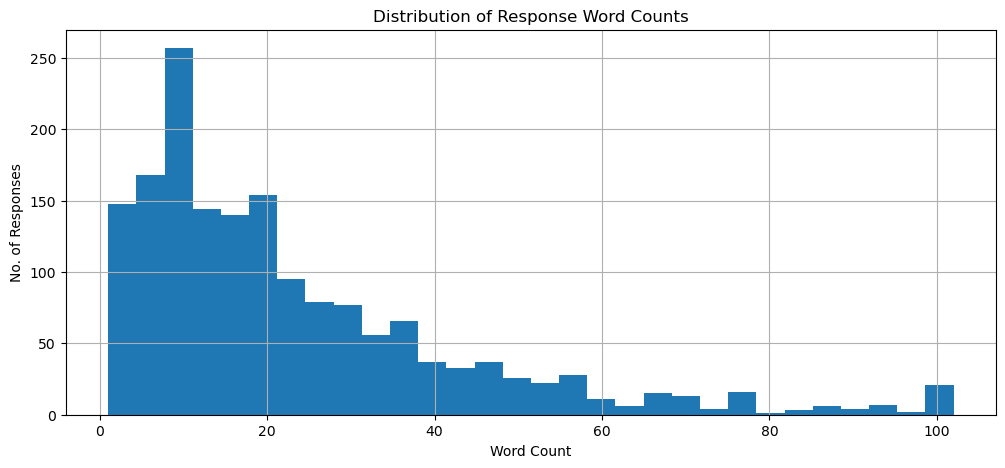

In [104]:
plt.figure(figsize=(12, 5))

copy_df["word_count"].clip(
    upper=copy_df["word_count"].quantile(0.99)
).hist(bins=30)

plt.title("Distribution of Response Word Counts") #this is capped at the 99th percentile

plt.xlabel("Word Count")
plt.ylabel("No. of Responses")

plt.show()

## Screening Responses


In [105]:
closed_answer_pattern = re.compile(
    r"^(yes|no|y|n|true|false|t|f|agree|disagree|"
    r"strongly agree|strongly disagree|not applicable|n/?a|none|"
    r"don't know|do not know|unsure|no response|no comment|nil|-)\s*[.!?]*$",
    flags=re.IGNORECASE
)

In [106]:
#function for detecting closed-ended responses

def flag_response(text):
    if pd.isna(text) or not str(text).strip():
        return "blank"

    cleaned = str(text).strip()

    if closed_answer_pattern.fullmatch(cleaned):
        return "likely_closed_or_noninformative"

    if len(cleaned.split()) < 3:
        return "short_response_review"

    return "retain_for_topic_modeling"

In [107]:
copy_df["screening_flag"] = copy_df["raw_response"].apply(flag_response)


print(copy_df["screening_flag"].value_counts(dropna=False))



screening_flag
retain_for_topic_modeling    1647
short_response_review          29
Name: count, dtype: int64


In [108]:
# Step 7.2 — Split flagged and retained records.

closed_or_noninformative = copy_df[
    copy_df["screening_flag"] == "likely_closed_or_noninformative"
].copy()

short_review = copy_df[
    copy_df["screening_flag"] == "short_response_review"
].copy()

analysis_df = copy_df[
    copy_df["screening_flag"].isin([
        "retain_for_topic_modeling",
        "short_response_review"
    ])
].copy()

print("All nonblank responses:", len(copy_df))

print(
    "Likely closed-form / non-informative:",
    len(closed_or_noninformative)
)

print(
    "Short responses retained for review:",
    len(short_review)
)

print(
    "Responses entering preprocessing:",
    len(analysis_df)
)

display(
    closed_or_noninformative[
        ["raw_response", "screening_flag"]
    ].head(25)
)

All nonblank responses: 1676
Likely closed-form / non-informative: 0
Short responses retained for review: 29
Responses entering preprocessing: 1676


,raw_response,screening_flag


In [109]:
# Step 8.1 — Define a light text-cleaning function.

def clean_text(text):

    if pd.isna(text):
        return ""

    text = str(text).lower()

    # Removing URLs.
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Removing email addresses.
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.\w+\b",
        " ",
        text
    )

    # Keep alphabetic characters and apostrophes.
    text = re.sub(
        r"[^a-z\s']",
        " ",
        text
    )

    # Normalise whitespace.
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text

In [110]:
analysis_df["clean_text"] = (
    analysis_df["raw_response"].apply(clean_text)
)

# Remove responses that became empty after cleaning.
analysis_df = analysis_df[
    analysis_df["clean_text"].str.strip().ne("")
].copy()

print("Responses after cleaning:", len(analysis_df))

display(
    analysis_df[["raw_response", "clean_text"]].head(12)
)

Responses after cleaning: 1676


,raw_response,clean_text
0,"Better handwriting, hard to follow lecture sli...",better handwriting hard to follow lecture slid...
1,Variety of office hours so that all can get he...,variety of office hours so that all can get he...
2,"Better lecture, no more ""is that good?""",better lecture no more is that good
3,Online resources; post more notes on line,online resources post more notes on line
4,It would be better if we can have an equation ...,it would be better if we can have an equation ...
5,Be specific as to what will be asked for on th...,be specific as to what will be asked for on th...
6,Make class smaller,make class smaller
7,Make document summarizing all important equati...,make document summarizing all important equati...
8,Email class notes after every class.,email class notes after every class
9,Online resources,online resources


## TF-IDF

TF-IDF represents each response using numerical weights associated with words and phrases.

Steps:
1. Cleaning the text
2. Tokenization
3. Calculating the TF-IDF Scores
4. Creat an TF-IDF Matrix


In [111]:
#Create count and TF-IDF document-term matrices.

MIN_DF = 2
MAX_DF = 0.95

count_vectorizer = CountVectorizer(
    stop_words="english",
    min_df=MIN_DF,
    max_df=MAX_DF,
    ngram_range=(1, 1),
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b"
)

tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    min_df=MIN_DF,
    max_df=MAX_DF,
    ngram_range=(1, 2),
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b"
)

try:

    count_matrix = count_vectorizer.fit_transform(
        analysis_df["clean_text"]
    )

    tfidf_matrix = tfidf_vectorizer.fit_transform(
        analysis_df["clean_text"]
    )

except ValueError as exc:

    raise ValueError(
        "The vocabulary is empty. Try MIN_DF=1, "
        "relax MAX_DF, or inspect cleaned text."
    ) from exc


count_terms = count_vectorizer.get_feature_names_out()

tfidf_terms = tfidf_vectorizer.get_feature_names_out()

print("Count matrix:", count_matrix.shape)

print("TF-IDF matrix:", tfidf_matrix.shape)

Count matrix: (1676, 1370)
TF-IDF matrix: (1676, 3115)


,word,count
0,class,519
1,students,419
2,lecture,327
3,lectures,311
4,office,298
5,hours,293
6,time,256
7,questions,212
8,professors,211
9,problems,210


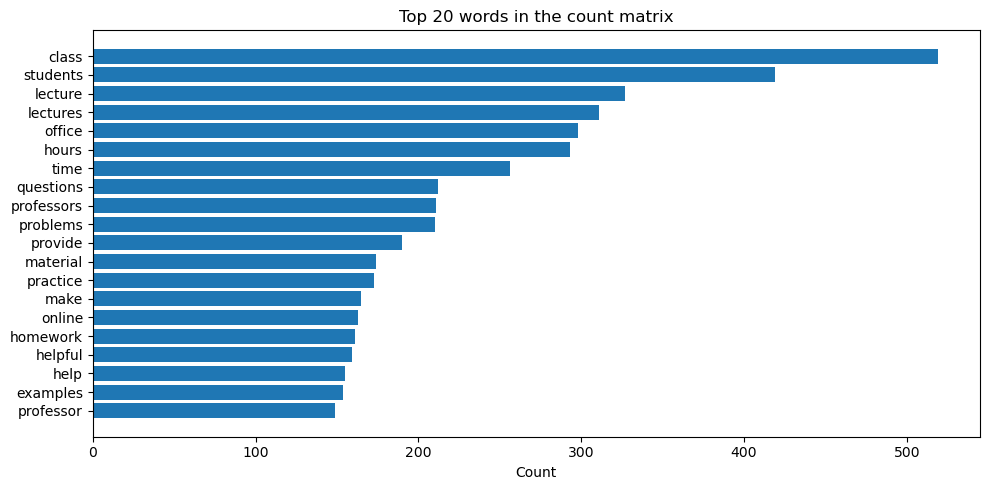

In [112]:
# Step 9.2 — Inspect the most frequent words in the count matrix.

word_counts = np.asarray(
    count_matrix.sum(axis=0)
).ravel()

top_idx = word_counts.argsort()[::-1][:20]

top_words_df = pd.DataFrame({
    "word": count_terms[top_idx],
    "count": word_counts[top_idx]
})

display(top_words_df)

plt.figure(figsize=(10, 5))

plt.barh(
    top_words_df["word"][::-1],
    top_words_df["count"][::-1]
)

plt.title("Top 20 words in the count matrix")

plt.xlabel("Count")

plt.tight_layout()

plt.show()

Checking that the TF-IDF matrrix corresponds to the correct responses

In [113]:
#number of responses retained for analysis.
print(len(analysis_df))

1676


In [114]:
#Dimensions/shape of the TF-IDF matrix.
print(tfidf_matrix.shape)

# Rows represent student responses.
# Columns represent words or phrases.

(1676, 3115)


In [115]:
#number of unique words/vocabulary
print (len(tfidf_terms))

3115


In [116]:
assert len(analysis_df) >= 3, ("ArithmeticError: The number of responses retained for analysis is less than 3. ")

#this is just to ensure that there are enough responses to attempt clustering.


## K-Means Clustering

What K-Means does is to use these numerical representations to group similar responses into clusters based on the language they share.

Steps:
1. Selecting the number of clusters(K)
2. Evaluating the clusters (using silhoutte scores)
3. Train the K-means model
4. Assigning cluster labels
5. Extraction of Keywords
6. Interpretation of the clusters
7. Visualisation and exportation of results

In [117]:
#Step 1
#Initialization of the minimum and maximum number of clusters (K) for K-means clustering.


MIN_K = 2               #creating 2 clsters

MAX_K = min(10, len(analysis_df) - 1)              #this ensures that the maximum K s smaller than the number of responses as required for silhouette evaluation.

candidate_k_values = list(range(MIN_K, MAX_K + 1))  #generating the candidate K values


print(candidate_k_values)

[2, 3, 4, 5, 6, 7, 8, 9, 10]


In [118]:
#Step 2: Evaluation (using silhouette score)

k_evaluation_results = []           #creating an empty list to store the evaluation results for each candidate K value

for k in candidate_k_values:
    print(f"Evaluating K={k} ...")

    kmeans_candidate = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,               #runs the algorithm 10 times using multiple initializations. Will select the best solution based on inertia.
        max_iter=300
    )

Evaluating K=2 ...
Evaluating K=3 ...
Evaluating K=4 ...
Evaluating K=5 ...
Evaluating K=6 ...
Evaluating K=7 ...
Evaluating K=8 ...
Evaluating K=9 ...
Evaluating K=10 ...


In [119]:
#Fitting the model and assigning each response to a cluster

candidate_labels = kmeans_candidate.fit_predict(
    tfidf_matrix
    )

In [120]:
# setting the maximum number of observations used to calculate the silhouette score. 

# Mainly, this is to avoid memory issues when calculating the silhouette score for large(r) datasets.

silhouette_sample_size = min(
        2000,
        len(analysis_df)
)

In [121]:
#calculating the silhouette score using cosine distance.

current_silhouette_score = silhouette_score(
        tfidf_matrix,
        candidate_labels,
        metric="cosine",
        sample_size=silhouette_sample_size,
        random_state=42
)

In [140]:
#storing the evaluation results for the current K value in a dictionary

k_evaluation_results.append({
    "k": k,
    "silhouette_score": current_silhouette_score,
    "inertia": kmeans_candidate.inertia_
    })

In [141]:
#converting the results into a DataFrame for easier analysis and visualization

k_evaluation_df = pd.DataFrame(k_evaluation_results)

In [142]:
#displaying the results in descending order (with the highest silhouette score)

display(
    k_evaluation_df.sort_values(
        by="silhouette_score",
        ascending=False
    ).reset_index(drop=True)
)

,k,silhouette_score,inertia
0,10,0.031264,1560.060625
1,10,0.031264,1560.060625
2,10,0.031264,1560.060625
3,10,0.031264,1560.060625
4,10,0.031264,1560.060625


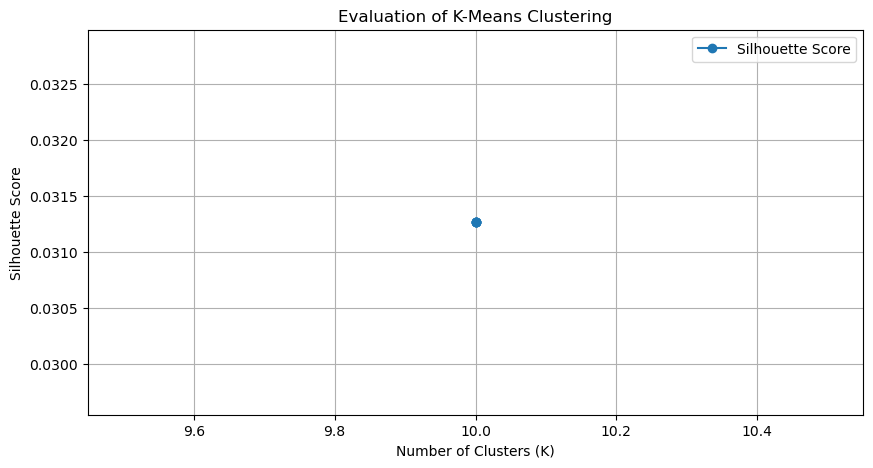

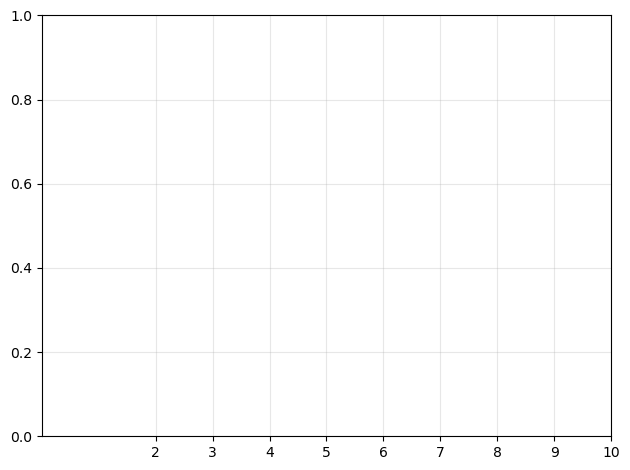

In [143]:
#Visualisation of silhouette scores and inertia values for each candidate K value.

#creating a figure - for comparing the candidate K values
plt.figure(figsize=(10, 5))


#plotting each candidate K against its silhouette score
plt.plot(
    k_evaluation_df["k"],
    k_evaluation_df["silhouette_score"],
    marker="o",
    label="Silhouette Score",
)

#adding a title and labels
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Evaluation of K-Means Clustering")
plt.legend()
plt.grid(True)
plt.show()

plt.xticks(candidate_k_values) #display each candidate K value on the x-axis/hortizontal axis
plt.grid(True, alpha=0.3) #adding a grid for easier comparison

plt.tight_layout()
plt.show()

In [146]:
#Selecting an initial value of K

#identiyfing the candidate k with the highest silhouette score
best_k_row = k_evaluation_df.loc[
    k_evaluation_df["silhouette_score"].idxmax()
]

#storing the selected number of clusters
Best_K = int(best_k_row["k"])

best_silhouette_score = float(     #storing its silhouette score as a float
    best_k_row["silhouette_score"]
)

# displaying the results

print(Best_K)


10


Fitting the final K-means Model

In [148]:
#fitting the final K-means model

start_time = time.time()     #recording the start time

kmeans_model = KMeans(       # initialising the final k-means model
    n_clusters=Best_K,
    random_state=42,
    n_init=10,
    max_iter=300
)

In [149]:
#fitting the model to the existing TF-IDF matrix and assigning each response to a cluster. Using fit_predict()

cluster_labels = kmeans_model.fit_predict(tfidf_matrix)

In [150]:
#Calculating the execution time
kmeans_runtime = time.time() - start_time

In [151]:
#displaying the results

print("Number of clusters:", Best_K)

print("Number of responses", len(cluster_labels))

#model runtime in seconds (rounded to 2 decimal places)
print(f"Final K-means model fitted with K={Best_K} clusters in {kmeans_runtime:.2f} seconds.")

Number of clusters: 10
Number of responses 1676
Final K-means model fitted with K=10 clusters in 88.97 seconds.


In [152]:
print(f"First 20 cluster assignments: {cluster_labels[:20]}")

First 20 cluster assignments: [6 3 6 7 5 5 5 5 7 5 5 5 7 3 7 2 5 5 2 4]


This is the main K-Means modelling step.
The model learns cluster centres from the TF-IDF matrix and assigns each response to a cluster.
The cluster numbers are identifiers, not rankings. Cluster 0 is not necessarily more important than cluster 1

## Attaching cluster assignments to our dataset

In [153]:
clustered_df = analysis_df.copy()  #creating a copy of the analysis dataframe

clustered_df["cluster"] = cluster_labels #attaching the cluster asssignment to each reponse

display(                                #diplaying the original response, cleaned text, source index and cluster assignment
    clustered_df[
        [
            "source_row_index",
            "raw_response",
            "clean_text",
            "cluster"
        ]
    ].head(15)
)


print(f"Clustered dataset shape: {clustered_df.shape}")

,source_row_index,raw_response,clean_text,cluster
0,0,"Better handwriting, hard to follow lecture sli...",better handwriting hard to follow lecture slid...,6
1,1,Variety of office hours so that all can get he...,variety of office hours so that all can get he...,3
2,2,"Better lecture, no more ""is that good?""",better lecture no more is that good,6
3,3,Online resources; post more notes on line,online resources post more notes on line,7
4,4,It would be better if we can have an equation ...,it would be better if we can have an equation ...,5
5,5,Be specific as to what will be asked for on th...,be specific as to what will be asked for on th...,5
6,6,Make class smaller,make class smaller,5
7,7,Make document summarizing all important equati...,make document summarizing all important equati...,5
8,8,Email class notes after every class.,email class notes after every class,7
9,9,Online resources,online resources,5


Clustered dataset shape: (1676, 7)


This makes it possible to trace every cluster assignment back to its source record.

In [155]:
# calculating cluster sizes

# Count the responses assigned to each cluster.
cluster_counts = (
    clustered_df["cluster"]
    .value_counts()
    .sort_index()
)

# Create a summary DataFrame.
cluster_summary = pd.DataFrame({
    "cluster": cluster_counts.index,
    "response_count": cluster_counts.values
})

# Calculate the percentage of responses in each cluster.
cluster_summary["percentage"] = (
    cluster_summary["response_count"]
    / len(clustered_df)
    * 100
).round(2)

# Display the summary.
display(cluster_summary)

# Confirm that the cluster counts equal the total responses.
print(
    "Total responses across clusters:",
    cluster_summary["response_count"].sum()
)

print(
    "Total analysed responses:",
    len(clustered_df)
)

,cluster,response_count,percentage
0,0,80,4.77
1,1,111,6.62
2,2,123,7.34
3,3,188,11.22
4,4,85,5.07
5,5,661,39.44
6,6,176,10.50
7,7,75,4.47
8,8,95,5.67
9,9,82,4.89


Total responses across clusters: 1676
Total analysed responses: 1676


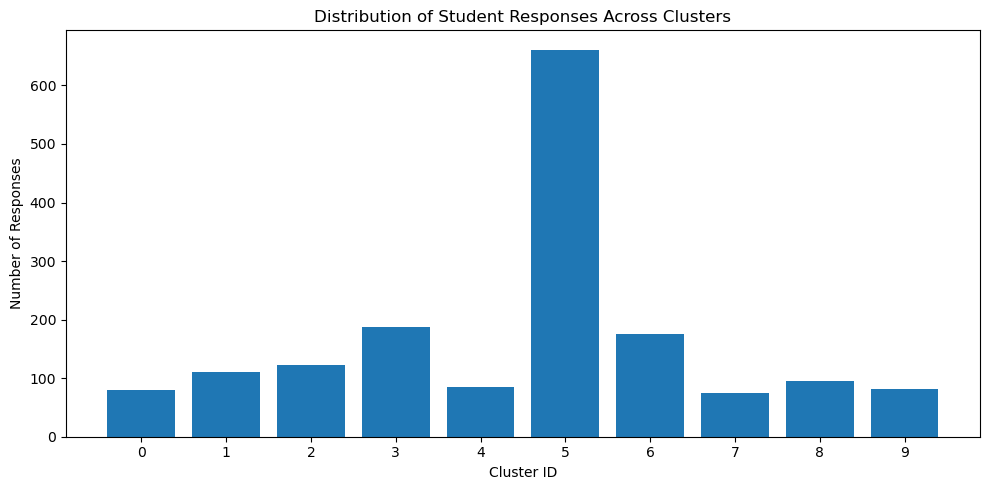

In [ ]:
#visualizing cluster sizes


# Creating a bar chart of the cluster distribution.
plt.figure(figsize=(10, 5))

plt.bar(
    cluster_summary["cluster"].astype(str),
    cluster_summary["response_count"]
)

plt.title("Distribution of Student Responses Across Clusters")

plt.xlabel("Cluster ID")

plt.ylabel("Number of Responses")

plt.tight_layout()

plt.show()

In [159]:
#Extracting top keywords

# Specify the number of keywords to display for each cluster.
TOP_N_TERMS = 15

# Retrieve the cluster centroids learned by K-Means.
#
# Each centroid represents the average TF-IDF feature vector
# of the responses assigned to that cluster.
cluster_centres = kmeans_model.cluster_centers_

# Create a dictionary to store the top terms.
cluster_top_terms = {}

# Examine every cluster.
for cluster_id in range(Best_K):

    # Retrieve the centroid for the current cluster.
    centre = cluster_centres[cluster_id]

    # Identify the features with the highest centroid weights.
    top_term_indices = np.argsort(centre)[::-1][
        :TOP_N_TERMS
    ]

    # Convert feature indices into their corresponding terms.
    top_terms = tfidf_terms[top_term_indices]

    # Store the keywords for later analysis.
    cluster_top_terms[cluster_id] = list(top_terms)

    # Display the results.
    print(f"\nCluster {cluster_id}")
    print("-" * 50)

    for rank, term in enumerate(top_terms, start=1):
        print(f"{rank}. {term}")


Cluster 0
--------------------------------------------------
1. examples
2. examples class
3. class
4. concepts
5. provide examples
6. provide
7. problems
8. going
9. class examples
10. examples problems
11. lecture
12. time
13. solve
14. going examples
15. showing

Cluster 1
--------------------------------------------------
1. practice
2. practice problems
3. problems
4. exams
5. practice exams
6. provide
7. solutions
8. provide practice
9. tests
10. exam
11. practice tests
12. midterms
13. providing
14. practice exam
15. resources

Cluster 2
--------------------------------------------------
1. lectures
2. recorded
3. recording
4. recorded lectures
5. record
6. recording lectures
7. record lectures
8. engaging
9. live
10. live lectures
11. helpful
12. class
13. pre
14. having
15. students

Cluster 3
--------------------------------------------------
1. hours
2. office hours
3. office
4. help
5. offer
6. available
7. class
8. offer office
9. online
10. extra
11. hold
12. provide off

In [ ]:
#inspecting responses

#creating a cluster interpreation table/summary
##visualizing the cluster & plot the cluster